# Minimizing T-Count for AQFT

In this notebook we implement AQFT circuit 1 in [[1]] in Qiskit.

AQFT stands for approximate quantum fourier transform, and the idea is to remove rotation gates in QFT such that the rotation angles are below a certain tolerance. By choosing this tolerance well, the affect this has when replacing QFT with AQFT in certain quantum algorithms can be incredibly minimal.

The paper we follow outlines a way to reduce the number of Toffoli gates using adders with a special state, in order to implement the rotation gates in AQFT.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import Math
from qiskit.compiler import transpile
from qiskit.quantum_info import Statevector
from qiskit.synthesis.qft import synth_qft_full

from approximate_qft.aqft import *

## Converting IPGT to Addition
We follow the Supplementary document supplied by the authors in [[1]].

The phase gradient transformation (PGT) and its inverse (IPGT) on an $n$-qubit system are defined by:

$$ PGT\ket{x} =  e^{2\pi i x / 2^n} \ket{x} $$
$$ IPGT\ket{x} =  e^{- 2\pi i x / 2^n} \ket{x} $$

IPGT can be represented by a set of $Z^\theta$ gates. The following figure taken from Fig S1 in the supplementary document in [[1]] gives this

<img src="img/ipgt.png" width="200"/>

However IPGT can also be implemented using an adder, when adding $x$ with the following special state $\psi$:

$$ \psi = QFT\ket{1} = \frac{1}{\sqrt{2^n}} \sum_{k=0}^{2^n - 1} e^{2\pi i k/ 2^n} \ket{k} $$

Explicitly:

$$
\begin{align*}
Adder\ket{x}\ket{\psi} &= \frac{1}{\sqrt{2^n}} \sum_{k=0}^{2^n - 1} e^{2\pi i k/ 2^n} \ket{x}\ket{x+k \mod 2^n}  \\
&= \frac{1}{\sqrt{2^n}} \sum_{k=0}^{2^n - 1} e^{-2\pi i x/ 2^n} e^{2\pi i (x+k)/ 2^n} \ket{x}\ket{x+k \mod 2^n} \\
&= \frac{1}{\sqrt{2^n}} e^{-2\pi i x/ 2^n} \sum_{k=0}^{2^n - 1}  e^{2\pi i (x+k)/ 2^n} \ket{x}\ket{x+k \mod 2^n} \\
&= e^{-2\pi i x/ 2^n} \frac{1}{\sqrt{2^n}}  \sum_{k=0}^{2^n - 1}  e^{2\pi i k/ 2^n} \ket{x}\ket{k \mod 2^n} \\
&= e^{-2\pi i x/ 2^n} \ket{x}\ket{\psi}\\
&= IPGT\ket{x}\ket{\psi}
\end{align*}
$$

Note that $\psi$ is unchanged hence can be reused for multiple adders. Also note that if we have $\psi$ above with $n$ qubits, then we can use the first $k$-qubits of $\psi$ a $k$-qubit adder to implement IPGT on a $k$-qubit system. These two properties are used in [[1]] and hence in our Qiskit implementation.

Here we verify in Qiskit that inverse PGT can be implemented using an adder with the special state $\psi$. For easier verification we prepare the state $\psi$, apply the adder and then uncompute it.

In [2]:
x_register = QuantumRegister(2, name="x")
psi_register = QuantumRegister(2, name="psi")
adder_ancilla_register = QuantumRegister(1, name="Adder Ancilla (carry 0)")

ipgt_test_circuit = QuantumCircuit(x_register, psi_register, adder_ancilla_register)

ipgt_test_circuit.append(state_preparation(2), psi_register)
ipgt_test_circuit.append(
    curraco_ripple_carry_adder_modulo(2),
    adder_ancilla_register[:] + psi_register[:] + x_register[:],
)
ipgt_test_circuit.append(state_uncompute(2), psi_register)

# x=0, n=2. Hence IPGT|x> = |0>
initial_state = Statevector.from_label("0" + "00" + "00")
evolved_state = initial_state.evolve(ipgt_test_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto "
        + evolved_state.draw("latex").data[2:]
    )
)

# x=1, n=2. Hence IPGT|x> = e^{-2\pi i / 2^2} |1> = e^{-i\pi/2} |1> = -i|1>
initial_state = Statevector.from_label("0" + "00" + "01")
evolved_state = initial_state.evolve(ipgt_test_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto "
        + evolved_state.draw("latex").data[2:]
    )
)

# x=2, n=2. Hence IPGT|x> = e^{-2\pi i * 2 / 2^2} |3> = e^{-i\pi} |2> = -|2>
initial_state = Statevector.from_label("0" + "00" + "10")
evolved_state = initial_state.evolve(ipgt_test_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto "
        + evolved_state.draw("latex").data[2:]
    )
)

# x=3, n=2. Hence IPGT|x> = e^{-2\pi i * 3 / 2^2} |3> = e^{-3i\pi/2} |3> = i|3>
initial_state = Statevector.from_label("0" + "00" + "11")
evolved_state = initial_state.evolve(ipgt_test_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto "
        + evolved_state.draw("latex").data[2:]
    )
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Which is exactly as expected noting that the last two qubits qubits from the left correspond to $x$.

The curraco_ripple_carry_adder_modulo function is an implementation of the circuit from [[3]], specifically the modulo $2^n$ version stated in that paper. The adder is thouroughly tested in test_aqft.py.

The state_preparation prepares $\psi$ by applying an X gate to the least significant bit (i.e applying the transformation $\ket{0} \mapsto \ket{1}$) and then applying a QFT. 
The state_uncompute uncomputes $\psi$ by applying an IQFT then an X gate to the least significant bit.

Here is a diagram of the Curraco adder for 6 qubits:

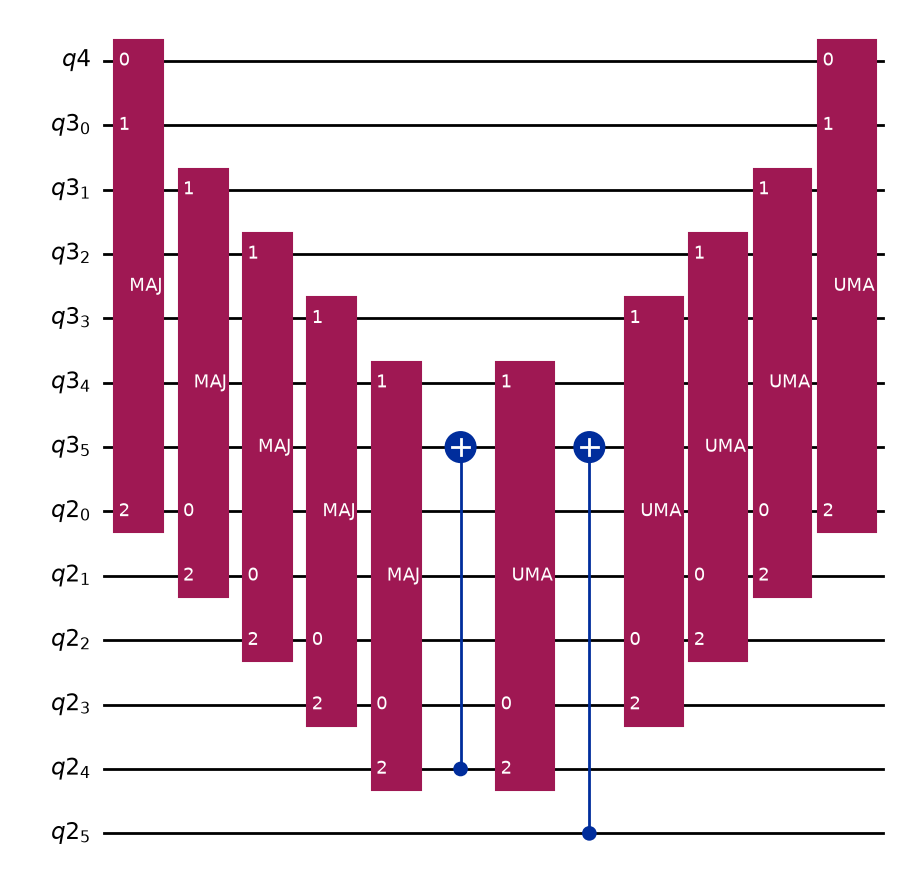

In [3]:
a = QuantumRegister(6)
b = QuantumRegister(6)
c = QuantumRegister(1)

cra_circuit = QuantumCircuit(c, b, a)
cra_circuit.append(curraco_ripple_carry_adder_modulo(6), c[:] + b[:] + a[:])

display(cra_circuit.decompose().draw("mpl"))

## Rearranging QFT subcircuits to form IPGT Gates
Each subcircuit in the QFT circuit outlined in [[2]] can be rearranged to be an IPGT gate surrounded by other $Z^\theta$ gates. The following figure taken from Fig 2 in [[1]] shows this.

![Figure 2](img/fig2.png "Figure 2")

The gates in the red boxes are then commuted (possible since the green box gates are diagonal) to the start of the QFT and likewise for the gates in the purple boxes to the end.

The Z gates in the green box are almost the IPGT gates in the previous section. To rectify this, we add an ancilla bit (in state $\ket{0}$ ) in the least significant bit position when we apply IPGT. We note that this ancilla bit remains unchanged since,

$$ Z^{-1}\ket{0} = Z\ket{0} = \ket{0}.$$

Alternatively adding a 0 in the least significant bit position is the same as multiplying by 2 (while increasing the dimension of the system by a multiple of 2). Hence if $x$ has $n$-qubits,

$$ IPGT(\ket{x}\ket{0}) =  IPGT(\ket{2x}) = e^{- 2\pi i (2x) / 2^{n+1}} \ket{2x} = e^{- 2\pi i x / 2^{n}} \ket{x}\ket{0} = IPGT(\ket{x})\ket{0}.$$

We verify that the Z gate configuration above can be made using adders and the trick used above.

In [4]:
number_of_qubits = 3

x_register = QuantumRegister(number_of_qubits, name="x")

ipgt_z_gate_circuit = QuantumCircuit(x_register)

for i in range(number_of_qubits):
    ipgt_z_gate_circuit.append(ZGate().power(-1 / 2 ** (i + 1)), [x_register[i]])


x_register = QuantumRegister(3, name="x")
psi_register = QuantumRegister(4, name="psi")
adder_ancilla_register = QuantumRegister(1, name="Adder Ancilla (carry 0)")
pgt_ancilla_register = QuantumRegister(1, name="PGT Ancilla")

ipgt_adder_test_circuit = QuantumCircuit(
    x_register, psi_register, adder_ancilla_register, pgt_ancilla_register
)

ipgt_adder_test_circuit.append(state_preparation(4), psi_register)
ipgt_adder_test_circuit.z(pgt_ancilla_register)
ipgt_adder_test_circuit.append(
    curraco_ripple_carry_adder_modulo(4),
    adder_ancilla_register[:]
    + psi_register[:]
    + x_register[:][::-1]
    + pgt_ancilla_register[:],
)
ipgt_adder_test_circuit.append(state_uncompute(4), psi_register)

print("The Z-gate implementation of IPGT gives:")

initial_state = Statevector.from_label("000")
evolved_state = initial_state.evolve(ipgt_z_gate_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

initial_state = Statevector.from_label("011")
evolved_state = initial_state.evolve(ipgt_z_gate_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

print("The Adder implementation of IPGT gives:")

initial_state = Statevector.from_label("0" + "0" + "0000" + "000")
evolved_state = initial_state.evolve(ipgt_adder_test_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)


initial_state = Statevector.from_label("0" + "0" + "0000" + "011")
evolved_state = initial_state.evolve(ipgt_adder_test_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

The Z-gate implementation of IPGT gives:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

The Adder implementation of IPGT gives:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

After commuting all the gates, and truncating all the Z-gates of power less that $1/2^b$ we get the following AQFT circuit. This is taken from Figure 3 in [[1]]

![Figure 3](img/fig3.png "Figure 3")

## Implementing the circuit in Qiskit
Using the diagram above we implement it in Qiskit using the adders mentioned above. We show a small snippet of how the IPGT in the green box gates above were implemented using adders.

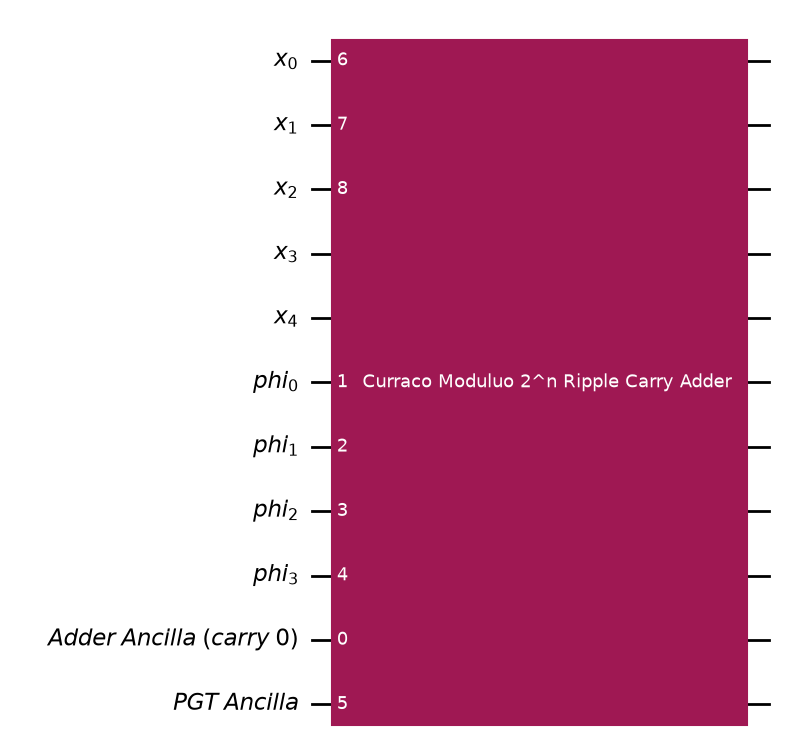

In [5]:
number_of_qubits = 5
b = 3
adder_bits = b + 1

x_register = QuantumRegister(number_of_qubits, name="x")
phi_register = QuantumRegister(adder_bits, name="phi")
adder_ancilla_register = QuantumRegister(1, name="Adder Ancilla (carry 0)")
pgt_ancilla_register = QuantumRegister(1, name="PGT Ancilla")

padded_ipgt_circuit = QuantumCircuit(
    x_register, phi_register, adder_ancilla_register, pgt_ancilla_register
)
truncated_bits = min(number_of_qubits, b)
padded_ipgt_circuit.append(
    curraco_ripple_carry_adder_modulo(truncated_bits + 1),
    adder_ancilla_register[:]
    + phi_register[0 : truncated_bits + 1]
    + pgt_ancilla_register[:]
    + x_register[0:truncated_bits],
)

display(padded_ipgt_circuit.draw("mpl"))

Note that we set the PGT ancila to be the least significant bit to be of b in the adder, $phi$ to b in the adder, and the adder ancilla bit is the c in the adder.

In the actual implementation in adder_after_prep, the a register is actually flipped beforehand due to significant bit ordering.

Note that if we set the number of bits we truncate to 0, i.e. we set $\psi$ to have $n+1$ bits, then the AQFT circuit above is just a QFT circuit. Hence we first verify the circuit in this boundary case against Qiskit's normal QFT gate,

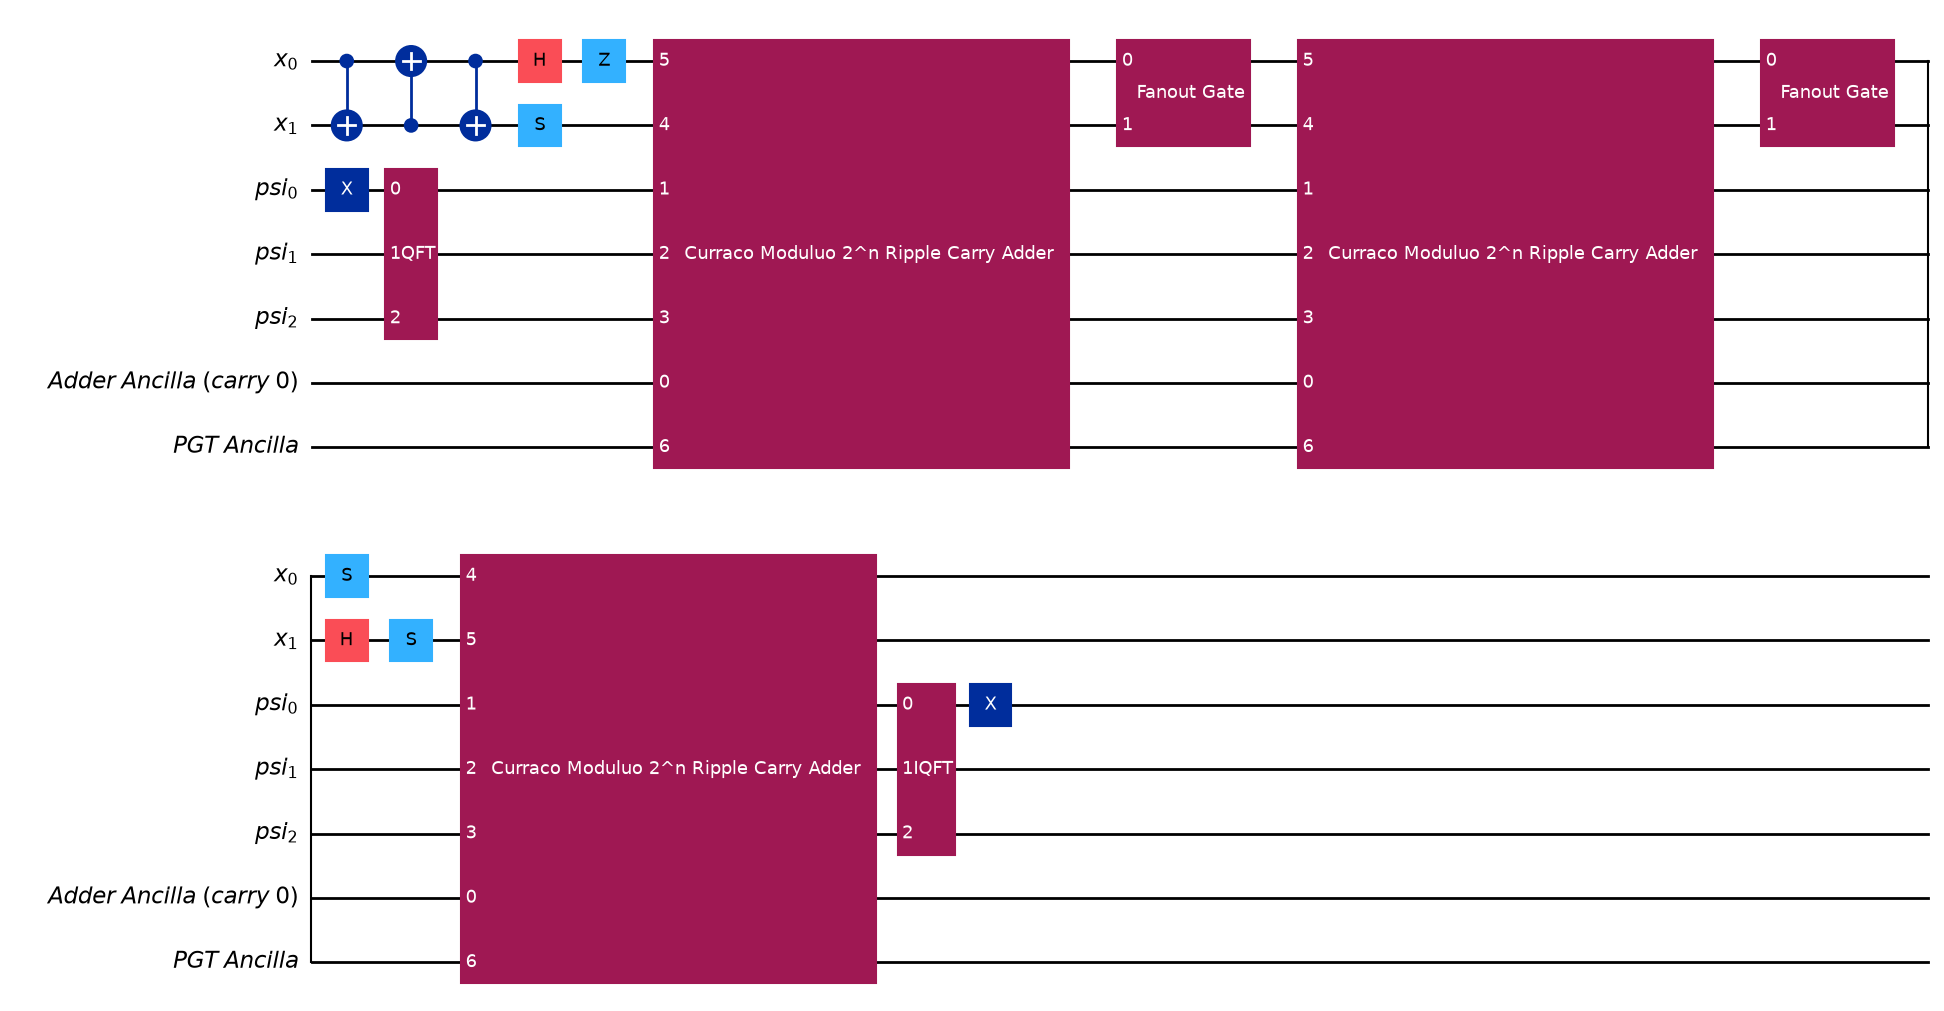

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Comparing this to Qiskit's implementation of QFT


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [6]:
x_register = QuantumRegister(2, name="x")
psi_register = QuantumRegister(3, name="psi")
adder_ancilla_register = QuantumRegister(1, name="Adder Ancilla (carry 0)")
pgt_ancilla_register = QuantumRegister(1, name="PGT Ancilla")

aqft_circuit = QuantumCircuit(
    x_register, psi_register, adder_ancilla_register, pgt_ancilla_register
)

aqft_circuit.append(
    aqft(2, 2),
    x_register[:]
    + psi_register[:]
    + adder_ancilla_register[:]
    + pgt_ancilla_register[:],
)

# Circuit Diagram

display(aqft_circuit.decompose().decompose().draw("mpl"))

# x=|0>, n=2
initial_state = Statevector.from_label("0" + "0" + "000" + "00")
evolved_state = initial_state.evolve(aqft_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

# x=|1>, n=2
initial_state = Statevector.from_label("0" + "0" + "000" + "01")
evolved_state = initial_state.evolve(aqft_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

# x=|2>, n=2
initial_state = Statevector.from_label("0" + "0" + "000" + "10")
evolved_state = initial_state.evolve(aqft_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

# x=|3>, n=2
initial_state = Statevector.from_label("0" + "0" + "000" + "11")
evolved_state = initial_state.evolve(aqft_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

print("Comparing this to Qiskit's implementation of QFT")

reg = QuantumRegister(2)
qft_circuit = QuantumCircuit(reg, name="QFT")
qft_circuit.append(synth_qft_full(2), reg)

initial_state = Statevector.from_label("00")
evolved_state = initial_state.evolve(qft_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

initial_state = Statevector.from_label("01")
evolved_state = initial_state.evolve(qft_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

initial_state = Statevector.from_label("10")
evolved_state = initial_state.evolve(qft_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)


initial_state = Statevector.from_label("11")
evolved_state = initial_state.evolve(qft_circuit)


display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

Which is exactly what we want. More tests of this nature are in the test files.

Now we consider the non boundary case. Note that we cannot test it against, for example Qiskit's approximate QFT implementation, since the approximation is done differently. In Qiskit, rotation gates below a tolerance are removed, whereas in the circuit above Z gates below a threshold are removed. This causes differences due to the specific Z gates right at the beginning and end (see the red and purple boxes in Fig 2), being removed.

Hence we test the adder implementation above against the same implemention purely using Z-gates:

In [7]:
number_of_qubits = 3
b = 2
x = "110"

x_register = QuantumRegister(number_of_qubits, name="x")
psi_register = QuantumRegister(b + 1, name="psi")
adder_ancilla_register = QuantumRegister(1, name="Adder Ancilla (carry 0)")
pgt_ancilla_register = QuantumRegister(1, name="PGT Ancilla")

aqft_adder_circuit = QuantumCircuit(
    x_register, psi_register, adder_ancilla_register, pgt_ancilla_register
)

aqft_adder_circuit.append(
    aqft(number_of_qubits, b),
    x_register[:]
    + psi_register[:]
    + adder_ancilla_register[:]
    + pgt_ancilla_register[:],
)

print("Here is the implementation using adders:")

initial_state = Statevector.from_label("0" + "0" + ("0" * (b + 1)) + x)
evolved_state = initial_state.evolve(aqft_adder_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

print("Comparing this to the reference implementation using only Z-Gates")

x_register = QuantumRegister(number_of_qubits, name="x")
aqft_z_gate_circuit = QuantumCircuit(x_register)
aqft_z_gate_circuit.append(
    aqft_z_gate_reference_implementation(number_of_qubits, b), x_register
)

initial_state = Statevector.from_label(x)
evolved_state = initial_state.evolve(aqft_z_gate_circuit)

display(
    Math(
        initial_state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

Here is the implementation using adders:


<IPython.core.display.Math object>

Comparing this to the reference implementation using only Z-Gates


<IPython.core.display.Math object>

Again more tests of this nature are in the test files.

## Experiments

Now we fix a precision and measure the T count as we increase the number of qubits.

We use the Clifford + T Basis when transpiling, but note that we only consider the T-Gates in the graphs below. We only transpile the main AQFT gate (the gate returned from the aqft_after_prep function), and ignore state preparation and uncomputation.

For a fixed error $\epsilon$ and number of qubits $n$, the number of bits $b$ we approximate to, is given by,
$$b = \lceil \log(n/\epsilon) \rceil.$$
This is again shown in [[1]].

In [8]:
def get_t_count_adder_aqft_implementation(number_of_qubits, b):
    # Clifford basis are the H, S and CX gates in Qiskit. CCX is the Toffoli gate
    basis_gates = ["h", "s", "cx", "ccx"]

    x_register = QuantumRegister(number_of_qubits, name="x")
    psi_register = QuantumRegister(b + 1, name="psi")
    adder_ancilla_register = QuantumRegister(1, name="Adder Ancilla (carry 0)")
    pgt_ancilla_register = QuantumRegister(1, name="PGT Ancilla")

    aqft_adder_circuit = QuantumCircuit(
        x_register, psi_register, adder_ancilla_register, pgt_ancilla_register
    )

    aqft_adder_circuit.append(
        aqft_after_prep(number_of_qubits, b),
        x_register[:]
        + psi_register[:]
        + adder_ancilla_register[:]
        + pgt_ancilla_register[:],
    )

    transpiled_circuit = transpile(aqft_adder_circuit, basis_gates=basis_gates)
    return transpiled_circuit.count_ops()["ccx"]


def t_count_for_fixed_precision(epsilon, start, end, step):
    x = list(range(start, end, step))
    y = []
    for i in x:
        b = aqft_error(i, epsilon)
        y.append(get_t_count_adder_aqft_implementation(i, b))

    return x, y


x_1, y_1 = t_count_for_fixed_precision(1 / 10, 10, 100, 1)
x_2, y_2 = t_count_for_fixed_precision(1 / 100, 10, 100, 1)
x_3, y_3 = t_count_for_fixed_precision(1 / 1000, 10, 100, 1)

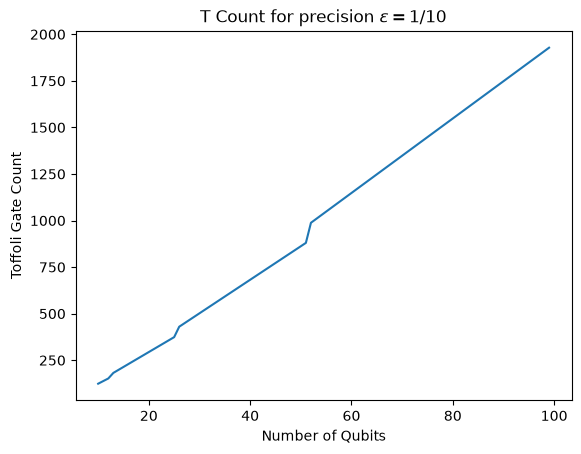

In [9]:
plt.plot(x_1, y_1)
plt.title(r"T Count for precision $\epsilon = 1/10$")
plt.xlabel(r"Number of Qubits")
plt.ylabel(r"Toffoli Gate Count")
plt.show()

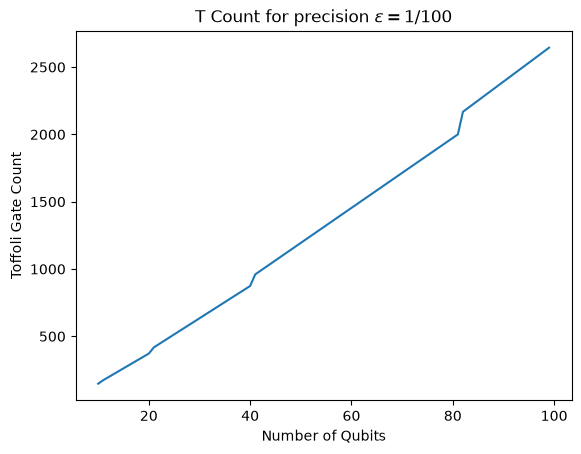

In [10]:
plt.plot(x_2, y_2)
plt.title(r"T Count for precision $\epsilon = 1/100$")
plt.xlabel(r"Number of Qubits")
plt.ylabel(r"Toffoli Gate Count")
plt.show()

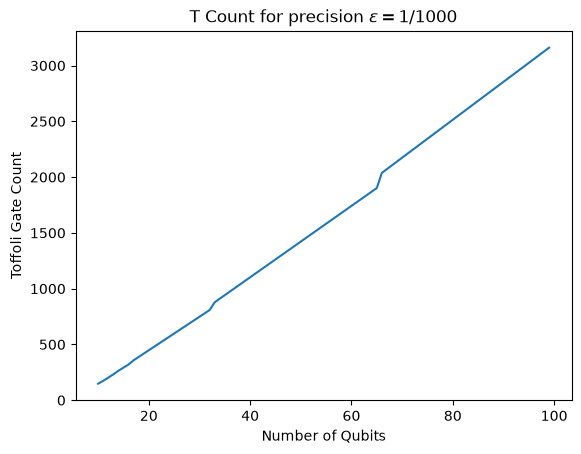

In [11]:
plt.plot(x_3, y_3)
plt.title(r"T Count for precision $\epsilon = 1/1000$")
plt.xlabel(r"Number of Qubits")
plt.ylabel(r"Toffoli Gate Count")
plt.show()

## Conclusions

The number of Toffoli gates used as the number of qubits increases for fixed precision behaves (upto a constant due to using a different adder implementation) as the author states in [[1]]. However this comes at a complicated state preparation step requiring Repeat-Until-Success circuits. If this state preparation is given, then this method gives a perfect synthesis of QFT using the Clifford + T basis.

I simplified the problem by ignoring the state preparation step, however this is a crucial part of making this algorithm work.

## References
<a id="1">[1]</a>
Park, B., Ahn, D. Reducing T-count and T-depth in approximate quantum Fourier transform circuits. Sci Rep 15, 37199 (2025). https://doi.org/10.1038/s41598-025-21087-2

<a id="2">[2]</a>
Nielsen, Michael A.; Chuang, Isaac L. (2012). Quantum Computation and Quantum Information.
ISBN 978-1-107-00217-3.

<a id="3">[3]</a>
Steven A. Cuccaro, Thomas G. Draper, Samuel A. Kutin, David Petrie Moulton
A new quantum ripple-carry addition circuit.
https://arxiv.org/abs/quant-ph/0410184